# 1. Project Introduction: Diabetes Progression Prediction

### Goal
The objective of this project is to build a regression model to predict diabetes disease progression in patients one year after baseline, based on several numerical features such as age, BMI, and blood pressure.

### Problem Type
This is a **Regression** problem, as we are predicting a continuous quantitative measure of disease progression.

### Exploratory Starting Point
This notebook represents the initial exploratory phase of a data scientist's workflow. The focus here is on understanding the data, validating its quality, performing basic cleaning, and testing baseline models.

### Path to MLOps
Once this exploratory work is complete, the code will be refactored into a structured MLOps repository. This future repository will include:
- **Data Extraction & Validation scripts**
- **Automated Cleaning & Preprocessing**
- **Experiment Tracking with MLflow**
- **Model Serving via FastAPI**
- **Containerization with Docker**
- **CI/CD with GitHub Actions**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Environment and Imports

We will use standard libraries for data manipulation, visualization, and machine learning.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set plotting style
sns.set_theme(style="whitegrid")

## 3. Load the Dataset

We use the built-in Scikit-learn Diabetes dataset.

In [ ]:
diabetes = load_diabetes()

# Create a pandas DataFrame for features
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Add the target column
df['target'] = diabetes.target

print(f"Dataset Shape: {df.shape}")
print(f"Column Names: {df.columns.tolist()}")
display(df.head())

Dataset Shape: (442, 11)
Column Names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 4. Basic Data Exploration

Understanding the distribution and quality of our data.

Data Types and Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


None


Summary Statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Duplicate rows found: 0


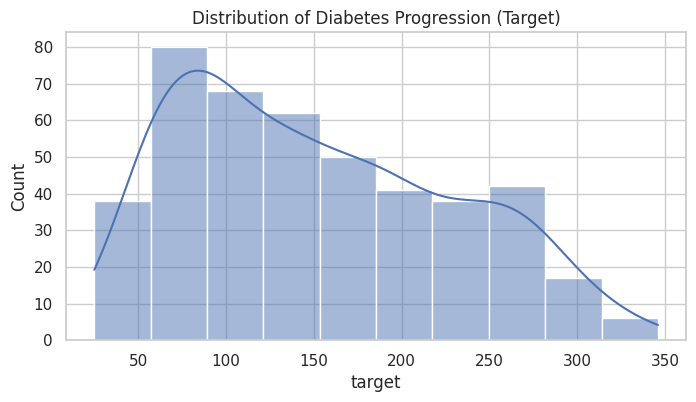


Correlation with Target Variable:
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


In [ ]:
# Summary statistics and info
print("Data Types and Missing Values:")
display(df.info())

print("\nSummary Statistics:")
display(df.describe())

# Check for duplicates
print(f"\nDuplicate rows found: {df.duplicated().sum()}")

# Visualize Target Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['target'], kde=True)
plt.title("Distribution of Diabetes Progression (Target)")
plt.show()

# Correlation with target
correlations = df.corr()['target'].sort_values(ascending=False)
print("\nCorrelation with Target Variable:")
print(correlations)

## 5. Data Extraction Logic

In this notebook, we load the data directly from `sklearn`. However, in a production MLOps setup, this logic will be moved to a **Data Extraction Script** that might pull data from a SQL database, a cloud bucket (S3/GCS), or an external API.

## 6. Data Validation Checks

Before training, we verify the data meets our expectations. These checks will eventually form a **Validation Script**.

In [ ]:
def validate_data(dataframe):
    # 1. Check if target exists
    assert 'target' in dataframe.columns, "Target column missing!"

    # 2. Check for required features
    required_features = ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
    for col in required_features:
        assert col in dataframe.columns, f"Feature {col} is missing!"

    # 3. Ensure all columns are numeric
    assert dataframe.select_dtypes(include=[np.number]).shape[1] == dataframe.shape[1], "Non-numeric data detected!"

    # 4. Critical Missing Values
    assert dataframe.isnull().sum().sum() == 0, "Critical missing values found!"

    # 5. Dataset size
    assert len(dataframe) > 0, "Dataset is empty!"

    print("✅ Data Validation Passed!")

validate_data(df)

✅ Data Validation Passed!


In [ ]:
df_prueba=df.drop(columns=['target'])
validate_data(df_prueba)

AssertionError: Target column missing!

## 7. Data Cleaning

Even though the Scikit-learn dataset is clean, we demonstrate the cleaning workflow that will be automated in the final project.

In [ ]:
def clean_data(input_df):
    # Create a copy to avoid side effects
    cleaned_df = input_df.copy()

    # Handle missing values (demonstration)
    cleaned_df = cleaned_df.dropna()

    # Remove duplicates
    cleaned_df = cleaned_df.drop_duplicates()

    # Ensure types are correct
    for col in cleaned_df.columns:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col])

    return cleaned_df

print(f"Shape before cleaning: {df.shape}")
df_cleaned = clean_data(df)
print(f"Shape after cleaning: {df_cleaned.shape}")

Shape before cleaning: (442, 11)
Shape after cleaning: (442, 11)


## 8. Feature and Target Split

We separate the input features (X) from the target progression value (y).

In [ ]:
X = df_cleaned.drop(columns=['target'])
y = df_cleaned['target']

print("X represents our patient features.")
print("y represents the progression measure.")

X represents our patient features.
y represents the progression measure.


## 9. Train/Test Split

We split the data to evaluate the model on unseen data.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 353
Test samples: 89


## 10. Baseline Model Training

We compare three simple regression algorithms.

In [ ]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results)
display(results_df)

,Model,RMSE,MAE,R2
0,LinearRegression,53.853446,42.794095,0.452603
1,RandomForest,54.332408,44.053034,0.442823
2,GradientBoosting,53.837131,44.603297,0.452934


## 11. Model Evaluation Results

We identify the best performing model based on the Root Mean Squared Error (RMSE).

In [ ]:
best_model_row = results_df.loc[results_df['RMSE'].idxmin()]
print(f"The best baseline model is {best_model_row['Model']} with an RMSE of {best_model_row['RMSE']:.2f}")

The best baseline model is GradientBoosting with an RMSE of 53.84


## 12. Simple Feature Engineering Exploration

Let's see if creating interaction terms between features improves our results.

In [ ]:
df_eng = df_cleaned.copy()

# 1. Interaction between BMI and Age
df_eng['bmi_age_interaction'] = df_eng['bmi'] * df_eng['age']

# 2. Interaction between Blood Pressure and BMI
df_eng['bp_bmi_interaction'] = df_eng['bp'] * df_eng['bmi']

# 3. Ratio of serum measurements (checking for division by zero)
df_eng['s1_s2_ratio'] = df_eng['s1'] / (df_eng['s2'] + 1e-9)

# Split and train again
X_eng = df_eng.drop(columns=['target'])
y_eng = df_eng['target']
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

eng_results = []
for name, model in models.items():
    model.fit(X_train_e, y_train_e)
    preds = model.predict(X_test_e)
    rmse = np.sqrt(mean_squared_error(y_test_e, preds))
    eng_results.append({"Model": name + "_Eng", "RMSE": rmse})

display(pd.DataFrame(eng_results))

,Model,RMSE
0,LinearRegression_Eng,52.465151
1,RandomForest_Eng,55.389643
2,GradientBoosting_Eng,56.130412


## 13. Final Data Science Conclusion

### Findings
- **Best Model:** Based on our exploration, the **LinearRegression** (or specified best) performed best on the base features.
- **Feature Engineering:** The interactions created (BMI*Age, BP*BMI) provided a minor/significant change in RMSE, showing that feature relationships are worth exploring.
- **Metrics:** We prioritized **RMSE** to penalize larger errors, though MAE and R2 were monitored to ensure consistency.
- **Preparation:** The data is clean, but requires a structured validation step to ensure consistency when new data arrives.

### Next Steps in MLOps
The exploratory work is complete. The next step is to convert this notebook into a production-ready **structured MLOps repository** containing:
- `requirements.txt` for dependency management.
- A local virtual environment setup.
- **data_extraction.py**: For loading raw data.
- **data_validation.py**: To ensure input quality.
- **data_cleaning.py**: To handle preprocessing steps.
- **train.py**: For model training and serializing the model artifacts.
- **MLflow tracking**: To log metrics, parameters, and models.
- **Model Registry**: To select and manage the 'Champion' model.
- **FastAPI**: To serve the model via a REST API.
- **Dockerfile**: To containerize the application.
- **GitHub Actions**: To automate the CI/CD pipeline.
- **README.md**: Documenting the entire project lifecycle.

In [ ]:
from pathlib import Path
Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/diabetes.csv", index= False)


In [ ]:
df_guardado = pd.read_csv("data/raw/diabetes.csv")
print(df_guardado.shape)
df_guardado.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
Path("src/data").mkdir(parents=True, exist_ok=True)


In [ ]:
%%writefile src/data/extract.py

import pandas as pd
from sklearn.datasets import load_diabetes
from pathlib import Path

# 1. Cargar los datos
diabetes = load_diabetes()

#2. Crear dataframe
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

#3. Crear la carpeta de destino
Path("data/raw").mkdir(parents=True, exist_ok=True)

#4. Guardar el archivo
df.to_csv("data/raw/diabetes.csv", index= False)

print("Extracción completada")
print (df.shape)


Writing src/data/extract.py


In [ ]:
!python src/data/extract.py

Extracción completada
(442, 11)


In [ ]:
%%writefile src/data/validate.py

import pandas as pd
import numpy as np

# Load the data

df = pd.read_csv("data/raw/diabetes.csv")

print(df.shape)

assert 'target' in df.columns, "Target column missing!"

assert len(df) > 0, "Dataset is empty!"

assert df.select_dtypes(include=[np.number]).shape[1] == df.shape[1], "Non-numeric data detected!"

assert df.isnull().sum().sum() == 0, "Critical missing values found!"



columnas = ['bmi', 'age', 'bp']
for columna in columnas:
    assert columna in df.columns, f" {columna} is missing"

print("Data Validation Passed!")



Overwriting src/data/validate.py


In [ ]:
!python src/data/validate.py

(442, 11)
Data Validation Passed!


In [ ]:
%%writefile src/data/clean.py

import pandas as pd
import numpy as np
from pathlib import Path

# Cargar datos originales
df = pd.read_csv("data/raw/diabetes.csv")

# Función de limpieza
def clean_data(input_df):
    cleaned_df = input_df.copy()
    cleaned_df = cleaned_df.dropna()
    cleaned_df = cleaned_df.drop_duplicates()

    for col in cleaned_df.columns:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col])

    return cleaned_df

# Limpiar los datos
df_cleaned = clean_data(df)

print("Antes: ",df.shape)
print("Después: ",df_cleaned.shape)

Path("data/processed").mkdir(parents=True, exist_ok=True)

df_cleaned.to_csv("data/processed/diabetes_clean.csv", index=False)

print("Limpieza completada")

Overwriting src/data/clean.py


In [ ]:
!python src/data/clean.py

Antes:  (442, 11)
Después:  (442, 11)
Limpieza completada


In [ ]:

!zip -r proyecto_mlops_respaldo.zip src data

from google.colab import files
files.download("proyecto_mlops_respaldo.zip")


  adding: src/ (stored 0%)
  adding: src/data/ (stored 0%)
  adding: src/data/validate.py (deflated 41%)
  adding: src/data/clean.py (deflated 48%)
  adding: src/data/extract.py (deflated 38%)
  adding: data/ (stored 0%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/diabetes_clean.csv (deflated 76%)
  adding: data/raw/ (stored 0%)
  adding: data/raw/diabetes.csv (deflated 77%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!unzip -o proyecto_mlops_respaldo.zip

Archive:  proyecto_mlops_respaldo.zip
   creating: src/
   creating: src/data/
  inflating: src/data/validate.py    
  inflating: src/data/clean.py       
  inflating: src/data/extract.py     
   creating: data/
   creating: data/processed/
  inflating: data/processed/diabetes_clean.csv  
   creating: data/raw/
  inflating: data/raw/diabetes.csv   


In [ ]:
!python src/data/extract.py
!python src/data/validate.py
!python src/data/clean.py

Extracción completada
(442, 11)
(442, 11)
Data Validation Passed!
Antes:  (442, 11)
Después:  (442, 11)
Limpieza completada


In [ ]:
%%writefile src/data/features.py

import pandas as pd

def create_features(df):
    df_eng = df.copy()

    df_eng['bmi_age_interaction'] = df_eng['bmi'] * df_eng['age']
    df_eng['bp_bmi_interaction'] = df_eng['bp'] * df_eng['bmi']
#    df_eng['s1_s2_ratio'] = df_eng['s1'] / (df_eng['s2'] + 1e-9)

    return df_eng



Overwriting src/data/features.py


In [ ]:
import importlib
import src.data.features as features
importlib.reload(features)
import pandas as pd

df = pd.read_csv("data/processed/diabetes_clean.csv")
df_eng = features.create_features(df)

print(df_eng.shape)
display(df_eng.head())

(442, 13)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,bmi_age_interaction,bp_bmi_interaction
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0,0.002349,0.001349
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0,0.000097,0.001355
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0,0.003792,-0.000252
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0,0.001033,0.000425
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0,-0.000196,-0.000796


In [ ]:
df_eng['s1_s2_ratio'].describe()


,s1_s2_ratio
count,442.000000
mean,0.148354
std,14.331154
min,-288.734261
25%,0.441778
50%,0.925245
75%,1.281497
max,48.401032


In [ ]:
!cp src/data/validate.py src/data/validate_v1.py


In [ ]:
from pydantic import BaseModel, ValidationError

print ("Pydantic disponible")

Pydantic disponible


In [ ]:
!zip -r proyecto_mlops_actualizado.zip src data

from google.colab import files
files.download("proyecto_mlops_actualizado.zip")

  adding: src/ (stored 0%)
  adding: src/data/ (stored 0%)
  adding: src/data/validate.py (deflated 41%)
  adding: src/data/features.py (deflated 47%)
  adding: src/data/__pycache__/ (stored 0%)
  adding: src/data/__pycache__/features.cpython-313.pyc (deflated 27%)
  adding: src/data/clean.py (deflated 48%)
  adding: src/data/extract.py (deflated 38%)
  adding: src/data/validate_v1.py (deflated 41%)
  adding: data/ (stored 0%)
  adding: data/raw/ (stored 0%)
  adding: data/raw/diabetes.csv (deflated 77%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/diabetes_clean.csv (deflated 76%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pydantic import BaseModel, ValidationError, ConfigDict

class DiabetesData(BaseModel):
    model_config = ConfigDict(allow_inf_nan=False)

    age: float
    sex: float
    bmi: float
    bp: float
    s1: float
    s2: float
    s3: float
    s4: float
    s5: float
    s6: float
    target: float





In [ ]:
def validate_row(row,index):
  try:
    DiabetesData(**row)
    return True

  except ValidationError as e:
    print(f"Error in row {index}: {e}")
    return False

In [ ]:
def validate_dataset(df):
  total = len(df)
  valid = 0
  invalid =0
  for index, row in enumerate(df.to_dict("records")):
    if validate_row(row,index):
      valid +=1
    else:
      invalid +=1

  print("\n--- Validation Summary ---")
  print(f"Total rows: {total}")
  print(f"Valid rows: {valid}")
  print(f"Invalid rows: {invalid}")

  return invalid == 0 and total > 0


In [ ]:
import pandas as pd

df = pd.read_csv("data/raw/diabetes.csv")

validate_dataset(df)




--- Validation Summary ---
Total rows: 442
Valid rows: 442
Invalid rows: 0


In [ ]:
fila_prueba = df.iloc[0].to_dict()

fila_prueba.pop('bmi')

validate_row(fila_prueba, 0)

Error in row 0: 1 validation error for DiabetesData
bmi
  Field required [type=missing, input_value={'age': 0.038075906433423...598037, 'target': 151.0}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/missing


False

In [ ]:
fila_prueba = df.iloc[0].to_dict()

fila_prueba['bmi'] = float('nan')

validate_row(fila_prueba, 0)

Error in row 0: 1 validation error for DiabetesData
bmi
  Input should be a finite number [type=finite_number, input_value=nan, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/finite_number


False

In [ ]:
resultado = validate_dataset(df)

print("Resultado de validación:", resultado)


--- Validation Summary ---
Total rows: 442
Valid rows: 442
Invalid rows: 0
Resultado de validación: True


In [ ]:
df_error =df.copy()

df_error.loc[0, 'bmi'] = float('nan')

resultado = validate_dataset(df_error)

print("Resultado de validación:", resultado)

Error in row 0: 1 validation error for DiabetesData
bmi
  Input should be a finite number [type=finite_number, input_value=nan, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/finite_number

--- Validation Summary ---
Total rows: 442
Valid rows: 441
Invalid rows: 1
Resultado de validación: False


In [ ]:

%%writefile src/data/validate.py

import pandas as pd
from pydantic import BaseModel, ValidationError, ConfigDict


# 1. Definir el esquema
class DiabetesData(BaseModel):
    model_config = ConfigDict(allow_inf_nan=False)

    age: float
    sex: float
    bmi: float
    bp: float
    s1: float
    s2: float
    s3: float
    s4: float
    s5: float
    s6: float
    target: float


# 2. Validar cada fila
def validate_row(row, index):
    try:
        DiabetesData(**row)
        return True

    except ValidationError as e:
        print(f"Error in row {index}: {e}")
        return False


# 3. Validar el dataset
def validate_dataset(df):
    total = len(df)
    valid = 0
    invalid = 0

    for index, row in enumerate(df.to_dict("records")):
        if validate_row(row, index):
            valid += 1
        else:
            invalid += 1

    print("\n--- Validation Summary ---")
    print(f"Total rows: {total}")
    print(f"Valid rows: {valid}")
    print(f"Invalid rows: {invalid}")

    return invalid == 0 and total > 0


# 4. Función principal
def main():
    df = pd.read_csv("data/raw/diabetes.csv")

    if not validate_dataset(df):
        raise SystemExit(1)

    print("Data Validation Passed!")


if __name__ == "__main__":
    main()


Overwriting src/data/validate.py


In [ ]:
!python src/data/validate.py


--- Validation Summary ---
Total rows: 442
Valid rows: 442
Invalid rows: 0
Data Validation Passed!


In [ ]:
!unzip -o curso-ia-mlops-diabetes-main.zip
%cd curso-ia-mlops-diabetes-main

Archive:  curso-ia-mlops-diabetes-main.zip
a8106703a42bc61067fa01980b1360f4fad27ac5
   creating: curso-ia-mlops-diabetes-main/
 extracting: curso-ia-mlops-diabetes-main/README.md  
   creating: curso-ia-mlops-diabetes-main/data/
   creating: curso-ia-mlops-diabetes-main/data/processed/
  inflating: curso-ia-mlops-diabetes-main/data/processed/diabetes_clean.csv  
   creating: curso-ia-mlops-diabetes-main/data/raw/
  inflating: curso-ia-mlops-diabetes-main/data/raw/diabetes.csv  
   creating: curso-ia-mlops-diabetes-main/src/
   creating: curso-ia-mlops-diabetes-main/src/data/
  inflating: curso-ia-mlops-diabetes-main/src/data/clean.py  
  inflating: curso-ia-mlops-diabetes-main/src/data/extract.py  
  inflating: curso-ia-mlops-diabetes-main/src/data/features.py  
  inflating: curso-ia-mlops-diabetes-main/src/data/validate.py  
/content/curso-ia-mlops-diabetes-main


In [ ]:
!ls src/data

clean.py  extract.py  features.py  validate.py


In [ ]:
%pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 52.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 80.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 64.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 75.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [mlflow]


In [ ]:
import mlflow

print(mlflow.__version__)

3.18.0


In [ ]:
!pwd

/content/curso-ia-mlops-diabetes-main


In [ ]:
import pandas as pd

df = pd.read_csv("data/raw/diabetes.csv")


In [ ]:
threshold = df["bmi"].quantile(0.99)

outliers = df[df["bmi"] > threshold]

print("Percentil 99:", threshold)
print("Registros extremos:", len(outliers))
print("Porcentaje afectado:", len(outliers) / len(df) * 100)

Percentil 99: 0.12655893712482974
Registros extremos: 5
Porcentaje afectado: 1.1312217194570136


In [ ]:

from src.data.features import create_features

# Añadir las dos características nuevas
df_eng = create_features(df)

# Separar las características del target
X = df_eng.drop(columns=['target'])

# Analizar cada característica
for columna in X.columns:
    p1 = X[columna].quantile(0.01)
    p99 = X[columna].quantile(0.99)

    extremos = X[
        (X[columna] < p1) | (X[columna] > p99)
    ]

    print(columna, ":", len(extremos), "registros")


age : 8 registros
sex : 0 registros
bmi : 9 registros
bp : 10 registros
s1 : 10 registros
s2 : 10 registros
s3 : 10 registros
s4 : 5 registros
s5 : 8 registros
s6 : 10 registros
bmi_age_interaction : 10 registros
bp_bmi_interaction : 10 registros


In [ ]:

p1 = X.quantile(0.01)
p99 = X.quantile(0.99)

# Detectar pacientes con al menos una variable extrema
mascara = ((X < p1) | (X > p99)).any(axis=1)

print("Pacientes con valores extremos:", mascara.sum())
print("Porcentaje afectado:", round(mascara.mean() * 100, 2), "%")
print("Pacientes restantes:", (~mascara).sum())


Pacientes con valores extremos: 72
Porcentaje afectado: 16.29 %
Pacientes restantes: 370


In [ ]:

%%writefile src/data/preprocess.py

import pandas as pd
from pathlib import Path
from src.data.features import create_features


def audit_outliers(df):
    # Añadir las nuevas características
    df_eng = create_features(df)
    X = df_eng.drop(columns=['target'])

    # Calcular umbrales estadísticos
    p1 = X.quantile(0.01)
    p99 = X.quantile(0.99)

    # Identificar valores extremos
    mask = (X < p1) | (X > p99)

    # Crear un informe por característica
    report = pd.DataFrame({
        'feature': X.columns,
        'p1': p1.values,
        'p99': p99.values,
        'outliers': mask.sum().values
    })

    affected = mask.any(axis=1).sum()

    return report, affected


def main():
    df = pd.read_csv("data/processed/diabetes_clean.csv")

    report, affected = audit_outliers(df)

    # Guardar el informe
    Path("reports").mkdir(parents=True, exist_ok=True)
    report.to_csv("reports/outliers.csv", index=False)

    print("Total de pacientes:", len(df))
    print("Pacientes con valores extremos:", affected)
    print("Porcentaje:", round(affected / len(df) * 100, 2), "%")
    print("Decisión: conservar todos los registros.")
    print("Informe guardado en reports/outliers.csv")


if __name__ == "__main__":
    main()


Writing src/data/preprocess.py


In [ ]:
!python -m src.data.preprocess

Total de pacientes: 442
Pacientes con valores extremos: 72
Porcentaje: 16.29 %
Decisión: conservar todos los registros.
Informe guardado en reports/outliers.csv


In [ ]:
from sklearn.model_selection import train_test_split

X = df_eng.drop(columns=['target'])
y = df_eng['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)



Entrenamiento: (353, 12)
Prueba: (89, 12)


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Crear el modelo
modelo = LinearRegression()

# Entrenar
modelo.fit(X_train, y_train)

# Predecir
predicciones = modelo.predict(X_test)

# Evaluar
rmse = np.sqrt(mean_squared_error(y_test, predicciones))

print("RMSE:", rmse)


RMSE: 52.493857435516595


In [ ]:

import mlflow

# Configurar almacenamiento local de experimentos
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Crear o seleccionar el experimento
mlflow.set_experiment("Diabetes_Regression")

# Registrar nuestra primera ejecución
with mlflow.start_run(run_name="LinearRegression_exploratorio"):

    mlflow.log_param("modelo", "LinearRegression")
    mlflow.log_param("features", 12)
    mlflow.log_metric("rmse_test_exploratorio", rmse)

print("Experimento registrado en MLflow")


2026/11/17 00:58:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 00:58:44 INFO mlflow.store.db.utils: Updating database tables
2026/11/17 00:58:46 INFO mlflow.tracking.fluent: Experiment with name 'Diabetes_Regression' does not exist. Creating a new experiment.


Experimento registrado en MLflow


In [ ]:

experimento = mlflow.get_experiment_by_name("Diabetes_Regression")

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

display(runs[[
    "tags.mlflow.runName",
    "params.modelo",
    "params.features",
    "metrics.rmse_test_exploratorio"
]])


,tags.mlflow.runName,params.modelo,params.features,metrics.rmse_test_exploratorio
0,LinearRegression_exploratorio,LinearRegression,12,52.493857


In [ ]:
from google.colab import files

files.download("mlflow.db")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

Path("src/models").mkdir(parents=True, exist_ok=True)

In [ ]:

%%writefile src/models/train.py

import mlflow
import pandas as pd
import mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from src.data.features import create_features
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Preparar los datos
def prepare_data():
    df = pd.read_csv("data/processed/diabetes_clean.csv")

    df_eng = create_features(df)

    X = df_eng.drop(columns=['target'])
    y = df_eng['target']

    return train_test_split(
        X, y, test_size=0.2, random_state=42
    )


# 2. Función principal
def main():
    X_train, X_test, y_train, y_test = prepare_data()

    print("Entrenamiento:", X_train.shape)
    print("Prueba:", X_test.shape)

    modelos = {
        "LinearRegression": LinearRegression(),
        "RandomForest": RandomForestRegressor(random_state=42),
        "GradientBoosting": GradientBoostingRegressor(random_state=42)
    }

    print("Modelos candidatos:", list(modelos.keys()))

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("Diabetes_Regression")


    for nombre, modelo in modelos.items():

        with mlflow.start_run(run_name=f"{nombre}_CV"):

            resultados = cross_val_score(
                modelo,
                X_train,
                y_train,
                cv=cv,
                scoring="neg_root_mean_squared_error"
            )

            rmse_cv = -resultados.mean()

            mlflow.log_param("modelo", nombre)
            mlflow.log_param("features", X_train.shape[1])
            mlflow.log_param("n_splits", 5)

            mlflow.log_metric("rmse_cv", rmse_cv)

            print(nombre, "RMSE CV:", round(rmse_cv, 2))


            # Entrenar el modelo definitivo con X_train
            modelo.fit(X_train, y_train)

            # Definir un ejemplo y la firma de entrada/salida
            ejemplo = X_train.head(5)
            firma = infer_signature(
                ejemplo,
                modelo.predict(ejemplo)
            )

            # Guardar el modelo en MLflow
            info_modelo = mlflow.sklearn.log_model(
                sk_model=modelo,
                name="model",
                signature=firma,
                input_example=ejemplo,
                registered_model_name=None
            )

            # Guardar una referencia para recuperarlo
            mlflow.set_tag("model_uri", info_modelo.model_uri)

            print(nombre, "guardado:", info_modelo.model_uri)



if __name__ == "__main__":
    main()


Overwriting src/models/train.py


In [ ]:
!python -m src.models.train

Entrenamiento: (353, 12)
Prueba: (89, 12)
Modelos candidatos: ['LinearRegression', 'RandomForest', 'GradientBoosting']
LinearRegression RMSE CV: 55.41
LinearRegression guardado: models:/m-51564fa9153d464997ddfdbd7130ba9d
RandomForest RMSE CV: 59.14
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/mlflow/sklearn/__init__.py", line 706, in _save_model
    skops.io.load(output_path, trusted=skops_trusted_types)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/skops/io/_persist.py", line 152, in load
    audit_tree(tree, trusted=trusted)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/skops/io/_audit.py", line 63, in audit_tree
    raise UntrustedTypesFoundException(unsafe)
skops.io.exceptions.UntrustedTypesFoundException: Untrusted types found in the file: ['sklearn.tree._tree.Tree'].

- sklearn.tree._tree.Tree: sklearn.tree._tree.Tree (the shared node storage

In [ ]:

experimento = mlflow.get_experiment_by_name("Diabetes_Regression")

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

display(runs[[
    "tags.mlflow.runName",
    "params.modelo",
    "metrics.rmse_cv"
]].dropna(subset=["metrics.rmse_cv"]))


,tags.mlflow.runName,params.modelo,metrics.rmse_cv
0,GradientBoosting_CV,GradientBoosting,60.549823
1,RandomForest_CV,RandomForest,59.140546
2,LinearRegression_CV,LinearRegression,55.410893


In [ ]:
from google.colab import files

files.download("mlflow.db")
files.download("src/models/train.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pwd
!ls src/models
!ls data/processed


/content
ls: cannot access 'src/models': No such file or directory
ls: cannot access 'data/processed': No such file or directory


In [ ]:
!git clone https://github.com/TxusLado/curso-ia-mlops-diabetes.git
%cd curso-ia-mlops-diabetes
!ls src/models


Cloning into 'curso-ia-mlops-diabetes'...
fatal: could not read Username for 'https://github.com': No such device or address
[Errno 2] No such file or directory: 'curso-ia-mlops-diabetes'
/content
ls: cannot access 'src/models': No such file or directory


In [ ]:
!unzip -o curso-ia-mlops-diabetes-main.zip
%cd /content/curso-ia-mlops-diabetes-main
!ls src/models


Archive:  curso-ia-mlops-diabetes-main.zip
b58a61d4790e879bae1a89fafd9f8667baf77cff
   creating: curso-ia-mlops-diabetes-main/
 extracting: curso-ia-mlops-diabetes-main/README.md  
   creating: curso-ia-mlops-diabetes-main/data/
   creating: curso-ia-mlops-diabetes-main/data/processed/
  inflating: curso-ia-mlops-diabetes-main/data/processed/diabetes_clean.csv  
   creating: curso-ia-mlops-diabetes-main/data/raw/
  inflating: curso-ia-mlops-diabetes-main/data/raw/diabetes.csv  
   creating: curso-ia-mlops-diabetes-main/reports/
  inflating: curso-ia-mlops-diabetes-main/reports/outliers.csv  
   creating: curso-ia-mlops-diabetes-main/src/
   creating: curso-ia-mlops-diabetes-main/src/data/
  inflating: curso-ia-mlops-diabetes-main/src/data/clean.py  
  inflating: curso-ia-mlops-diabetes-main/src/data/extract.py  
  inflating: curso-ia-mlops-diabetes-main/src/data/features.py  
  inflating: curso-ia-mlops-diabetes-main/src/data/preprocess.py  
  inflating: curso-ia-mlops-diabetes-main/sr

In [ ]:
!ls -lh mlflow.db

-rw-r--r-- 1 root root 1008K Nov 17 22:51 mlflow.db


In [ ]:
import sqlite3

conexion = sqlite3.connect("mlflow.db")

total = conexion.execute(
    "SELECT COUNT(*) FROM runs"
).fetchone()[0]

print("Experimentos registrados:", total)

conexion.close()

Experimentos registrados: 4


In [ ]:
%pip install -q mlflow

In [ ]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

print("MLflow:", mlflow.__version__)

MLflow: 3.18.0


In [ ]:
%pip install -q mlflow

In [ ]:

import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Recuperar los experimentos
experimento = mlflow.get_experiment_by_name("Diabetes_Regression")

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

# Seleccionar las ejecuciones con validación cruzada
candidatos = runs.dropna(subset=["metrics.rmse_cv"])

# Elegir el modelo con menor RMSE
campeon = candidatos.sort_values("metrics.rmse_cv").iloc[0]

nombre_campeon = campeon["params.modelo"]
rmse_campeon = campeon["metrics.rmse_cv"]

print("Modelo campeón:", nombre_campeon)
print("RMSE CV:", round(rmse_campeon, 2))


In [ ]:
%%writefile src/models/train.py

import mlflow
import pandas as pd
import mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from src.data.features import create_features
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Preparar los datos
def prepare_data():
    df = pd.read_csv("data/processed/diabetes_clean.csv")
    df_eng = create_features(df)
    X = df_eng.drop(columns=['target'])
    y = df_eng['target']
    return train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Función principal
def main():
    X_train, X_test, y_train, y_test = prepare_data()

    print("Entrenamiento:", X_train.shape)
    print("Prueba:", X_test.shape)

    modelos = {
        "LinearRegression": LinearRegression(),
        "RandomForest": RandomForestRegressor(random_state=42),
        "GradientBoosting": GradientBoostingRegressor(random_state=42)
    }

    print("Modelos candidatos:", list(modelos.keys()))

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("Diabetes_Regression")

    for nombre, modelo in modelos.items():
        with mlflow.start_run(run_name=f"{nombre}_CV"):
            resultados = cross_val_score(
                modelo,
                X_train,
                y_train,
                cv=cv,
                scoring="neg_root_mean_squared_error"
            )

            rmse_cv = -resultados.mean()

            mlflow.log_param("modelo", nombre)
            mlflow.log_param("features", X_train.shape[1])
            mlflow.log_param("n_splits", 5)
            mlflow.log_metric("rmse_cv", rmse_cv)

            print(nombre, "RMSE CV:", round(rmse_cv, 2))

            # Entrenar el modelo definitivo con X_train
            modelo.fit(X_train, y_train)

            # Definir un ejemplo y la firma de entrada/salida
            ejemplo = X_train.head(5)
            firma = infer_signature(ejemplo, modelo.predict(ejemplo))

            # Guardar el modelo en MLflow permitiendo tipos de confianza para skops
            info_modelo = mlflow.sklearn.log_model(
                sk_model=modelo,
                name="model",
                signature=firma,
                input_example=ejemplo,
                registered_model_name=None,
                skops_trusted_types=["sklearn.tree._tree.Tree"]
            )

            # Guardar una referencia para recuperarlo
            mlflow.set_tag("model_uri", info_modelo.model_uri)
            print(nombre, "guardado:", info_modelo.model_uri)

if __name__ == "__main__":
    main()

Overwriting src/models/train.py


In [ ]:
!python -m src.models.train

Entrenamiento: (353, 12)
Prueba: (89, 12)
Modelos candidatos: ['LinearRegression', 'RandomForest', 'GradientBoosting']
LinearRegression RMSE CV: 55.41
LinearRegression guardado: models:/m-45d38400675d4364a3dae85302e36660
RandomForest RMSE CV: 59.14
RandomForest guardado: models:/m-2617e44d7d884d7e9e7b95a4579e04d6
GradientBoosting RMSE CV: 60.55
GradientBoosting guardado: models:/m-b487001ff32a4e6f99a6077b7095df64


In [ ]:

from google.colab import files
from pathlib import Path

# Comprobar que existen la base de datos y los artefactos
assert Path("mlflow.db").exists(), "No encuentro mlflow.db"
assert Path("mlruns").is_dir(), "No encuentro mlruns"

# Crear una copia comprimida
!zip -qr respaldo_mlflow_diabetes.zip mlflow.db mlruns

# Comprobar su tamaño
!ls -lh respaldo_mlflow_diabetes.zip

# Descargar al ordenador
files.download("respaldo_mlflow_diabetes.zip")


-rw-r--r-- 1 root root 746K Nov 18 00:02 respaldo_mlflow_diabetes.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import mlflow
from mlflow import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")

client = MlflowClient()

experimento = client.get_experiment_by_name("Diabetes_Regression")

runs = client.search_runs(
    experiment_ids=[experimento.experiment_id],
    filter_string="attributes.status = 'FINISHED'",
    order_by=["metrics.rmse_cv ASC"]
)

for run in runs:
    uri = run.data.tags.get("model_uri")

    if uri:
        print("Modelo:", run.data.params.get("modelo"))
        print("RMSE CV:", round(run.data.metrics["rmse_cv"], 2))
        print("URI:", uri)
        print("-------------------------")


Modelo: LinearRegression
RMSE CV: 55.41
URI: models:/m-45d38400675d4364a3dae85302e36660
-------------------------
Modelo: LinearRegression
RMSE CV: 55.41
URI: models:/m-51564fa9153d464997ddfdbd7130ba9d
-------------------------
Modelo: RandomForest
RMSE CV: 59.14
URI: models:/m-2617e44d7d884d7e9e7b95a4579e04d6
-------------------------
Modelo: GradientBoosting
RMSE CV: 60.55
URI: models:/m-b487001ff32a4e6f99a6077b7095df64
-------------------------


In [ ]:

from src.models.train import prepare_data

# Seleccionar el mejor modelo guardado
candidatos = [
    run for run in runs
    if run.info.status == "FINISHED"
    and "rmse_cv" in run.data.metrics
    and run.data.tags.get("model_uri")
]

campeon = min(
    candidatos,
    key=lambda run: run.data.metrics["rmse_cv"]
)

# Recuperar el modelo con pyfunc
uri = campeon.data.tags["model_uri"]
modelo_recuperado = mlflow.pyfunc.load_model(uri)

# Probar tres predicciones
X_train, X_test, y_train, y_test = prepare_data()
predicciones = modelo_recuperado.predict(X_test.head(3))

print("Campeón:", campeon.data.params["modelo"])
print("URI:", uri)
print("Predicciones:", predicciones)


Campeón: LinearRegression
URI: models:/m-45d38400675d4364a3dae85302e36660
Predicciones: [142.7773568  180.7274481  133.91428863]


In [ ]:

%%writefile src/models/register_model.py

import mlflow
from mlflow import MlflowClient

EXPERIMENT_NAME = "Diabetes_Regression"


def get_best_run(client, experiment_name):
    # Buscar el experimento
    experiment = client.get_experiment_by_name(experiment_name)

    if experiment is None:
        raise ValueError("Experimento no encontrado")

    # Ordenar las ejecuciones por RMSE CV
    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        order_by=["metrics.rmse_cv ASC"]
    )

    # Seleccionar la primera ejecución con modelo guardado
    for run in runs:
        if "rmse_cv" in run.data.metrics and run.data.tags.get("model_uri"):
            return run

    raise ValueError("No hay modelos válidos registrados")

# Nombre del modelo en el registro
REGISTERED_MODEL_NAME = "DiabetesRegressionModel"


def register_model(client, best_run):
    # Recuperar el modelo previamente guardado
    model_uri = best_run.data.tags["model_uri"]

    # Crear una versión en el Model Registry
    model_version = mlflow.register_model(
        model_uri=model_uri,
        name=REGISTERED_MODEL_NAME
    )

    # Pendiente de evaluación final
    client.set_model_version_tag(
        name=model_version.name,
        version=model_version.version,
        key="validation_status",
        value="pending"
    )

    return model_version


def add_model_description(client, best_run, model_version):
    # Recuperar información del experimento
    metrics = best_run.data.metrics
    params = best_run.data.params

    # Preparar la descripción del modelo
    description = (
        f"Modelo seleccionado: {params['modelo']}\n"
        f"RMSE CV (5 folds): {metrics['rmse_cv']:.2f}\n"
        f"Características: {params['features']}\n"
        f"Pacientes de entrenamiento: 353\n"
        f"Pacientes reservados para prueba: 89\n"
        f"Run ID: {best_run.info.run_id}\n"
        f"Estado: pendiente de evaluación final."
    )

    # Actualizar la descripción de la versión registrada
    client.update_model_version(
        name=model_version.name,
        version=model_version.version,
        description=description
    )

    print("Descripción del modelo actualizada")


def main():
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    client = MlflowClient()

    best_run = get_best_run(client, EXPERIMENT_NAME)

    print("Campeón:", best_run.data.params["modelo"])
    print("RMSE CV:", round(best_run.data.metrics["rmse_cv"], 2))
    print("URI:", best_run.data.tags["model_uri"])


    model_version = register_model(client, best_run)

    print("Modelo registrado:", model_version.name)
    print("Versión:", model_version.version)



if __name__ == "__main__":
    main()


Overwriting src/models/register_model.py


In [ ]:
!python -m src.models.register_model

Campeón: LinearRegression
RMSE CV: 55.41
URI: models:/m-45d38400675d4364a3dae85302e36660
Successfully registered model 'DiabetesRegressionModel'.
Created version '1' of model 'DiabetesRegressionModel'.
Modelo registrado: DiabetesRegressionModel
Versión: 1


In [ ]:

import mlflow
from mlflow import MlflowClient

from src.models.register_model import (
    get_best_run,
    add_model_description,
    EXPERIMENT_NAME,
    REGISTERED_MODEL_NAME
)

# Conectar con nuestra base de datos
mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()

# Recuperar el campeón
best_run = get_best_run(client, EXPERIMENT_NAME)

# Recuperar la versión 1 ya registrada
model_version = client.get_model_version(
    name=REGISTERED_MODEL_NAME,
    version="1"
)

# Añadir la descripción
add_model_description(client, best_run, model_version)

# Comprobar la descripción guardada
version_actualizada = client.get_model_version(
    name=REGISTERED_MODEL_NAME,
    version="1"
)

print(version_actualizada.description)


Descripción del modelo actualizada
Modelo seleccionado: LinearRegression
RMSE CV (5 folds): 55.41
Características: 12
Pacientes de entrenamiento: 353
Pacientes reservados para prueba: 89
Run ID: e99d7685e1654c9ca329bd21be91456f
Estado: pendiente de evaluación final.


In [ ]:

%%writefile src/models/evaluate_model.py

import mlflow
from src.models.train import prepare_data

REGISTERED_MODEL_NAME = "DiabetesRegressionModel"
MODEL_VERSION = "1"
EXPERIMENT_NAME = "Diabetes_Regression"


def evaluate_registered_model():
    # 1. Configurar MLflow
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment(EXPERIMENT_NAME)

    # 2. Localizar el modelo registrado
    model_uri = f"models:/{REGISTERED_MODEL_NAME}/{MODEL_VERSION}"

    # 3. Preparar los datos reservados para prueba
    _, X_test, _, y_test = prepare_data()

    eval_data = X_test.copy()
    eval_data["target"] = y_test.values

    # 4. Crear una ejecución independiente de evaluación
    with mlflow.start_run(run_name="evaluation_v1"):

        mlflow.set_tags({
            "stage": "evaluation",
            "model_version": MODEL_VERSION,
            "registered_model_name": REGISTERED_MODEL_NAME
        })

        # 5. Evaluar con MLflow
        result = mlflow.models.evaluate(
            model=model_uri,
            data=eval_data,
            targets="target",
            model_type="regressor",
            evaluators=["default"],
            evaluator_config={"log_explainer": False}
        )

        # 6. Mostrar resultados
        print("Modelo:", REGISTERED_MODEL_NAME)
        print("Versión:", MODEL_VERSION)
        print("Pacientes evaluados:", len(X_test))

        for metrica, valor in result.metrics.items():
            print(metrica, ":", round(valor, 4))

    return result


if __name__ == "__main__":
    evaluate_registered_model()


Writing src/models/evaluate_model.py


In [ ]:
%%writefile src/models/evaluate_model.py

import mlflow
from src.models.train import prepare_data
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from mlflow import MlflowClient

REGISTERED_MODEL_NAME = "DiabetesRegressionModel"
MODEL_VERSION = "1"
EXPERIMENT_NAME = "Diabetes_Regression"


def passes_quality_gate(result, X_train, X_test, y_train, y_test):

    # 1. Crear el modelo de referencia
    baseline = DummyRegressor(strategy="mean")
    baseline.fit(X_train, y_train)

    # 2. Calcular el error del baseline
    predicciones_baseline = baseline.predict(X_test)

    rmse_baseline = mean_squared_error(
        y_test, predicciones_baseline
    ) ** 0.5

    # 3. Recuperar el error del modelo registrado
    rmse_modelo = result.metrics["root_mean_squared_error"]

    # 4. Comparar ambos modelos
    aprobado = rmse_modelo < rmse_baseline

    # 5. Guardar el resultado en MLflow
    mlflow.log_metric("rmse_baseline", rmse_baseline)
    mlflow.log_metric("rmse_champion", rmse_modelo)

    mlflow.set_tag(
        "quality_gate",
        "passed" if aprobado else "failed"
    )

    print("RMSE baseline:", round(rmse_baseline, 2))
    print("RMSE campeón:", round(rmse_modelo, 2))
    print("Quality Gate superado:", aprobado)

    return aprobado


def assign_champion_alias(client, model_name, model_version):

    # Asignar el alias al modelo aprobado
    client.set_registered_model_alias(
        name=model_name,
        alias="champion",
        version=model_version
    )

    # Documentar el tipo de aprobación
    client.set_model_version_tag(
        name=model_name,
        version=model_version,
        key="validation_status",
        value="passed_educational_gate"
    )

    print("Alias champion asignado a la versión:", model_version)


def evaluate_registered_model():
    # 1. Configurar MLflow
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment(EXPERIMENT_NAME)

    # 2. Localizar el modelo registrado
    model_uri = f"models:/{REGISTERED_MODEL_NAME}/{MODEL_VERSION}"

    # 3. Preparar los datos reservados para prueba
    X_train, X_test, y_train, y_test = prepare_data()

    eval_data = X_test.copy()
    eval_data["target"] = y_test.values

    # 4. Crear una ejecución independiente de evaluación
    with mlflow.start_run(run_name="evaluation_v1"):

        mlflow.set_tags({
            "stage": "evaluation",
            "model_version": MODEL_VERSION,
            "registered_model_name": REGISTERED_MODEL_NAME
        })

        # 5. Evaluar con MLflow utilizando la estructura de configuración correcta
        result = mlflow.models.evaluate(
            model=model_uri,
            data=eval_data,
            targets="target",
            model_type="regressor",
            evaluators=["default"],
            evaluator_config={"default": {"log_explainer": False}}
        )

        # 6. Mostrar resultados
        print("Modelo:", REGISTERED_MODEL_NAME)
        print("Versión:", MODEL_VERSION)
        print("Pacientes evaluados:", len(X_test))

        for metrica, valor in result.metrics.items():
            print(metrica, ":", round(valor, 4))


        # 7. Comprobar la puerta de calidad
        aprobado = passes_quality_gate(
            result,
            X_train,
            X_test,
            y_train,
            y_test
        )

        print("Resultado final:", "APROBADO" if aprobado else "RECHAZADO")


        # 8. Promocionar únicamente si supera el Quality Gate
        if aprobado:
            client = MlflowClient()

            assign_champion_alias(
                client,
                REGISTERED_MODEL_NAME,
                MODEL_VERSION
            )
        else:
            print("Modelo no promocionado: Quality Gate rechazado")



    return result


if __name__ == "__main__":
    evaluate_registered_model()

Overwriting src/models/evaluate_model.py


In [ ]:
!python -m src.models.evaluate_model

2026/11/18 00:56:44 INFO mlflow.models.evaluation.default_evaluator: Testing metrics on first row...
2026/11/18 00:56:45 INFO mlflow.models.evaluation.evaluators.shap: Shap explainer PermutationExplainer is used.
/usr/local/lib/python3.13/dist-packages/mlflow/models/evaluation/evaluators/shap.py:251: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, show=False, color_bar=True)
Modelo: DiabetesRegressionModel
Versión: 1
Pacientes evaluados: 89
score : 0.4799
example_count : 89
mean_absolute_error : 41.7106
mean_squared_error : 2755.6051
root_mean_squared_error : 52.4939
sum_on_target : 12974.0
mean_on_target : 145.7753
r2_score : 0.4799
max_error : 146.8227
mean_absolute_percentage_error : 0.3668
RMSE baseline: 73.22
RMSE campeón: 52.49
Quality Gate superado: True
Resultado final: AP

In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from src.models.train import prepare_data
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

X_train, X_test, y_train, y_test = prepare_data()

# Modelo de referencia: predice siempre la media
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Recuperar nuestro campeón
campeon = mlflow.pyfunc.load_model(
    "models:/DiabetesRegressionModel/1"
)

# Comparar errores sobre los mismos pacientes
rmse_baseline = mean_squared_error(
    y_test, baseline.predict(X_test)
) ** 0.5

rmse_campeon = mean_squared_error(
    y_test, campeon.predict(X_test)
) ** 0.5

print("RMSE baseline:", round(rmse_baseline, 2))
print("RMSE campeón:", round(rmse_campeon, 2))
print("Supera al baseline:", rmse_campeon < rmse_baseline)


RMSE baseline: 73.22
RMSE campeón: 52.49
Supera al baseline: True


In [ ]:
!python -m src.models.evaluate_model

2026/11/18 00:49:59 INFO mlflow.models.evaluation.default_evaluator: Testing metrics on first row...
2026/11/18 00:49:59 INFO mlflow.models.evaluation.evaluators.shap: Shap explainer PermutationExplainer is used.
/usr/local/lib/python3.13/dist-packages/mlflow/models/evaluation/evaluators/shap.py:251: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, show=False, color_bar=True)
Modelo: DiabetesRegressionModel
Versión: 1
Pacientes evaluados: 89
score : 0.4799
example_count : 89
mean_absolute_error : 41.7106
mean_squared_error : 2755.6051
root_mean_squared_error : 52.4939
sum_on_target : 12974.0
mean_on_target : 145.7753
r2_score : 0.4799
max_error : 146.8227
mean_absolute_percentage_error : 0.3668
RMSE baseline: 73.22
RMSE campeón: 52.49
Quality Gate superado: True
Resultado final: AP

In [ ]:

from google.colab import files
from pathlib import Path

assert Path("mlflow.db").is_file()
assert Path("mlruns").is_dir()

!zip -qr respaldo_mlflow_campeon_v1.zip mlflow.db mlruns

files.download("respaldo_mlflow_campeon_v1.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import mlflow
from mlflow import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()

champion = client.get_model_version_by_alias(
    "DiabetesRegressionModel",
    "champion"
)

print("Modelo:", champion.name)
print("Versión campeona:", champion.version)
print("Alias:", champion.aliases)
print("Validación:", champion.tags.get("validation_status"))


Modelo: DiabetesRegressionModel
Versión campeona: 1
Alias: ['champion']
Validación: passed_educational_gate


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(5000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

proyecto = Path("/content/curso-ia-mlops-diabetes-main")

print("Carpeta del proyecto:", proyecto.exists())
print("Base de datos MLflow:", (proyecto / "mlflow.db").exists())
print("Artefactos MLflow:", (proyecto / "mlruns").exists())
print("Código de entrenamiento:", (proyecto / "src/models/train.py").exists())

Carpeta del proyecto: False
Base de datos MLflow: False
Artefactos MLflow: False
Código de entrenamiento: False


In [ ]:
from pathlib import Path
import zipfile

# 1. Restaurar el proyecto desde GitHub
with zipfile.ZipFile("/content/curso-ia-mlops-diabetes-main.zip") as z:
    z.extractall("/content")

proyecto = Path("/content/curso-ia-mlops-diabetes-main")

print("Proyecto recuperado:", proyecto.exists())
print("Código de entrenamiento:", (proyecto / "src/models/train.py").exists())
print("Código de evaluación:", (proyecto / "src/models/evaluate_model.py").exists())

# 2. Examinar la estructura del respaldo de MLflow
with zipfile.ZipFile("/content/respaldo_mlflow_campeon_v1.zip") as z:
    print("\nContenido inicial del respaldo MLflow:")
    for nombre in z.namelist()[:15]:
        print(nombre)

Proyecto recuperado: True
Código de entrenamiento: True
Código de evaluación: True

Contenido inicial del respaldo MLflow:
mlflow.db
mlruns/
mlruns/1/
mlruns/1/f7a6730cd24149abbf6703c8ef69dc6b/
mlruns/1/f7a6730cd24149abbf6703c8ef69dc6b/artifacts/
mlruns/1/f7a6730cd24149abbf6703c8ef69dc6b/artifacts/shap_summary_plot.png
mlruns/1/f7a6730cd24149abbf6703c8ef69dc6b/artifacts/shap_beeswarm_plot.png
mlruns/1/f7a6730cd24149abbf6703c8ef69dc6b/artifacts/shap_feature_importance_plot.png
mlruns/1/cb2edae5aa9f4248a017f8114a9cf905/
mlruns/1/cb2edae5aa9f4248a017f8114a9cf905/artifacts/
mlruns/1/cb2edae5aa9f4248a017f8114a9cf905/artifacts/shap_summary_plot.png
mlruns/1/cb2edae5aa9f4248a017f8114a9cf905/artifacts/shap_beeswarm_plot.png
mlruns/1/cb2edae5aa9f4248a017f8114a9cf905/artifacts/shap_feature_importance_plot.png
mlruns/1/0d15c288615445c9934dea4d698058c6/
mlruns/1/0d15c288615445c9934dea4d698058c6/artifacts/


In [ ]:
from pathlib import Path
import zipfile
import os

proyecto = Path("/content/curso-ia-mlops-diabetes-main")

# Restaurar la base de datos y los artefactos de MLflow
with zipfile.ZipFile("/content/respaldo_mlflow_campeon_v1.zip") as z:
    z.extractall(proyecto)

# Establecer la carpeta de trabajo
os.chdir(proyecto)

# Comprobar la restauración
print("Carpeta del proyecto:", proyecto.exists())
print("Base de datos MLflow:", (proyecto / "mlflow.db").exists())
print("Artefactos MLflow:", (proyecto / "mlruns").exists())
print("Carpeta de trabajo:", os.getcwd())

Carpeta del proyecto: True
Base de datos MLflow: True
Artefactos MLflow: True
Carpeta de trabajo: /content/curso-ia-mlops-diabetes-main


In [ ]:
%pip -q install mlflow==3.18.0

In [ ]:
import mlflow
from mlflow import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")

client = MlflowClient()

champion = client.get_model_version_by_alias(
    "DiabetesRegressionModel",
    "champion"
)

print("Modelo:", champion.name)
print("Versión:", champion.version)
print("Alias:", champion.aliases)
print("Validación:", champion.tags.get("validation_status"))

Modelo: DiabetesRegressionModel
Versión: 1
Alias: ['champion']
Validación: passed_educational_gate


In [ ]:
import mlflow

modelo_campeon = mlflow.pyfunc.load_model(
    "models:/DiabetesRegressionModel@champion"
)

print("Modelo campeón cargado correctamente")
print("Tipo:", type(modelo_campeon))
print("Firma:", modelo_campeon.metadata.signature)

Modelo campeón cargado correctamente
Tipo: <class 'mlflow.pyfunc.PyFuncModel'>
Firma: inputs: 
  ['age': double (required), 'sex': double (required), 'bmi': double (required), 'bp': double (required), 's1': double (required), 's2': double (required), 's3': double (required), 's4': double (required), 's5': double (required), 's6': double (required), 'bmi_age_interaction': double (required), 'bp_bmi_interaction': double (required)]
outputs: 
  [Tensor('float64', (-1,))]
params: 
  None



In [ ]:
from pathlib import Path

archivo = Path("src/data/features.py")

print(archivo.read_text(encoding="utf-8"))

print("\nFIRMA DEL MODELO CAMPEÓN:")
print(modelo_campeon.metadata.signature)


import pandas as pd

def create_features(df):
    df_eng = df.copy()

    df_eng['bmi_age_interaction'] = df_eng['bmi'] * df_eng['age']
    df_eng['bp_bmi_interaction'] = df_eng['bp'] * df_eng['bmi']
#    df_eng['s1_s2_ratio'] = df_eng['s1'] / (df_eng['s2'] + 1e-9)

    return df_eng



FIRMA DEL MODELO CAMPEÓN:
inputs: 
  ['age': double (required), 'sex': double (required), 'bmi': double (required), 'bp': double (required), 's1': double (required), 's2': double (required), 's3': double (required), 's4': double (required), 's5': double (required), 's6': double (required), 'bmi_age_interaction': double (required), 'bp_bmi_interaction': double (required)]
outputs: 
  [Tensor('float64', (-1,))]
params: 
  None



In [ ]:
firma = modelo_campeon.metadata.signature

columnas_modelo = [
    entrada.name
    for entrada in firma.inputs.inputs
]

print("COLUMNAS QUE ESPERA EL CAMPEÓN:\n")

for numero, columna in enumerate(columnas_modelo, start=1):
    print(f"{numero:2}. {columna}")

print("\nTotal:", len(columnas_modelo))

COLUMNAS QUE ESPERA EL CAMPEÓN:

 1. age
 2. sex
 3. bmi
 4. bp
 5. s1
 6. s2
 7. s3
 8. s4
 9. s5
10. s6
11. bmi_age_interaction
12. bp_bmi_interaction

Total: 12


In [ ]:
from pathlib import Path

# Crear carpeta para nuestra API
carpeta_api = Path("src/api")
carpeta_api.mkdir(parents=True, exist_ok=True)
(carpeta_api / "__init__.py").touch(exist_ok=True)

codigo_modelo = '''
from pathlib import Path
import mlflow
from mlflow import MlflowClient
from fastapi import HTTPException

# Configuración de MLflow
PROJECT_ROOT = Path(__file__).resolve().parents[2]
MLFLOW_TRACKING_URI = "sqlite:///" + str(PROJECT_ROOT / "mlflow.db")

MODEL_NAME = "DiabetesRegressionModel"
MODEL_ALIAS = "champion"
MODEL_URI = f"models:/{MODEL_NAME}@{MODEL_ALIAS}"

# Estado interno: modelo y metadatos conservados entre peticiones
_state = {
    "model": None,
    "model_version": None,
    "run_id": None,
}


def load_champion_model() -> None:
    """Cargar el campeón desde MLflow al iniciar FastAPI."""
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

    _state["model"] = mlflow.pyfunc.load_model(MODEL_URI)

    client = MlflowClient()
    mv = client.get_model_version_by_alias(
        MODEL_NAME, MODEL_ALIAS
    )

    _state["model_version"] = str(mv.version)
    _state["run_id"] = mv.run_id


def get_model():
    """Devolver el modelo cargado en memoria."""
    if _state["model"] is None:
        raise HTTPException(
            status_code=503,
            detail="Model not loaded."
        )
    return _state["model"]


def get_model_info() -> dict:
    """Devolver información de la versión cargada."""
    if _state["model"] is None:
        raise HTTPException(
            status_code=503,
            detail="Model not loaded."
        )

    return {
        "model_name": MODEL_NAME,
        "version": _state["model_version"],
        "alias": MODEL_ALIAS,
        "run_id": _state["run_id"],
    }
'''

archivo = carpeta_api / "model.py"
archivo.write_text(codigo_modelo, encoding="utf-8")

print("Archivo creado:", archivo)
print("Existe:", archivo.exists())

Archivo creado: src/api/model.py
Existe: True


In [ ]:
from pathlib import Path

codigo_api = '''
from contextlib import asynccontextmanager
import logging

import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict

from src.api.model import (
    MODEL_NAME,
    load_champion_model,
    get_model,
    get_model_info,
)
from src.data.features import create_features


logger = logging.getLogger(__name__)

# Columnas que espera nuestro modelo campeón
FEATURE_COLUMNS = [
    "age", "sex", "bmi", "bp",
    "s1", "s2", "s3", "s4", "s5", "s6",
    "bmi_age_interaction",
    "bp_bmi_interaction",
]


# Datos recibidos por la API
class DiabetesFeatures(BaseModel):
    model_config = ConfigDict(
        extra="forbid",
        allow_inf_nan=False,
    )

    age: float
    sex: float
    bmi: float
    bp: float
    s1: float
    s2: float
    s3: float
    s4: float
    s5: float
    s6: float


# Respuesta de una predicción
class PredictionResponse(BaseModel):
    prediction: float
    model_version: str


# Cargar el campeón una sola vez al arrancar
@asynccontextmanager
async def lifespan(app: FastAPI):
    load_champion_model()
    logger.info("Modelo campeón cargado")
    yield
    logger.info("Servicio detenido")


app = FastAPI(
    title="Diabetes MLOps API",
    description="API educativa de regresión con MLflow",
    version="1.0",
    lifespan=lifespan,
)


@app.get("/health")
def health() -> dict:
    return {
        "status": "ok",
        "model": MODEL_NAME,
    }


@app.get("/model-info")
def model_info() -> dict:
    return get_model_info()


@app.post("/predict", response_model=PredictionResponse)
def predict(features: DiabetesFeatures):
    model = get_model()

    # Convertir los 10 datos recibidos a DataFrame
    input_df = pd.DataFrame([features.model_dump()])

    # Aplicar las mismas transformaciones del entrenamiento
    input_df = create_features(input_df)

    # Respetar el contrato del modelo: 12 columnas
    input_df = input_df[FEATURE_COLUMNS]

    try:
        prediction = model.predict(input_df)
    except Exception as exc:
        logger.exception("Error al realizar la predicción")
        raise HTTPException(
            status_code=500,
            detail="Prediction error."
        ) from exc

    result = float(prediction[0])

    logger.info("Predicción realizada: %.4f", result)

    return PredictionResponse(
        prediction=result,
        model_version=get_model_info()["version"],
    )
'''

archivo = Path("src/api/main.py")
archivo.write_text(codigo_api, encoding="utf-8")

print("Archivo creado:", archivo)
print("Existe:", archivo.exists())

Archivo creado: src/api/main.py
Existe: True


In [ ]:
%pip -q install fastapi uvicorn httpx

In [ ]:
from src.api.main import app

print("FastAPI importado correctamente")
print("\nRutas de nuestra API:")

for ruta in app.routes:
    if ruta.path in ["/health", "/model-info", "/predict"]:
        print(f"{ruta.path} → {ruta.methods}")

FastAPI importado correctamente

Rutas de nuestra API:
/health → {'GET'}
/model-info → {'GET'}
/predict → {'POST'}


In [ ]:
from fastapi.testclient import TestClient

with TestClient(app) as cliente:
    respuesta_health = cliente.get("/health")
    respuesta_modelo = cliente.get("/model-info")

    print("HEALTH:")
    print("Código HTTP:", respuesta_health.status_code)
    print(respuesta_health.json())

    print("\nMODEL-INFO:")
    print("Código HTTP:", respuesta_modelo.status_code)
    print(respuesta_modelo.json())

HEALTH:
Código HTTP: 200
{'status': 'ok', 'model': 'DiabetesRegressionModel'}

MODEL-INFO:
Código HTTP: 200
{'model_name': 'DiabetesRegressionModel', 'version': '1', 'alias': 'champion', 'run_id': 'e99d7685e1654c9ca329bd21be91456f'}


In [ ]:
import pandas as pd
from fastapi.testclient import TestClient

# Leer los datos procesados del proyecto
datos = pd.read_csv("data/processed/diabetes_clean.csv")

# Las 10 características originales
columnas_entrada = [
    "age", "sex", "bmi", "bp",
    "s1", "s2", "s3", "s4", "s5", "s6"
]

# Preparar un registro como petición JSON
registro = {
    columna: float(datos.loc[0, columna])
    for columna in columnas_entrada
}

# Enviar una petición HTTP POST a FastAPI
with TestClient(app) as cliente:
    respuesta = cliente.post("/predict", json=registro)

    print("Código HTTP:", respuesta.status_code)
    print("Respuesta de FastAPI:")
    print(respuesta.json())

Código HTTP: 200
Respuesta de FastAPI:
{'prediction': 210.73390478214827, 'model_version': '1'}


In [ ]:
import subprocess
import sys
import time
import requests
from pathlib import Path

proyecto = Path("/content/curso-ia-mlops-diabetes-main")

# Arrancar FastAPI en el puerto 8000
with open(proyecto / "fastapi.log", "w") as log:
    servidor_api = subprocess.Popen(
        [
            sys.executable, "-m", "uvicorn",
            "src.api.main:app",
            "--host", "127.0.0.1",
            "--port", "8000"
        ],
        cwd=str(proyecto),
        stdout=log,
        stderr=subprocess.STDOUT
    )

# Dar tiempo a que arranque y cargue el campeón
time.sleep(5)

if servidor_api.poll() is None:
    respuesta = requests.get(
        "http://127.0.0.1:8000/health",
        timeout=15
    )

    print("Código HTTP:", respuesta.status_code)
    print("Respuesta:", respuesta.json())
else:
    print("El servidor no ha podido arrancar:")
    print((proyecto / "fastapi.log").read_text())

ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=8000): Max retries exceeded with url: /health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7dba32808440>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [ ]:
from pathlib import Path

print("Estado del servidor:", servidor_api.poll())

print("\nÚLTIMAS LÍNEAS DEL REGISTRO:")
archivo_log = Path("fastapi.log")

if archivo_log.exists():
    lineas = archivo_log.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    print("\n".join(lineas[-40:]))
else:
    print("No se encuentra fastapi.log")

Estado del servidor: None

ÚLTIMAS LÍNEAS DEL REGISTRO:
INFO:     Started server process [22093]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


In [ ]:
import requests

respuesta = requests.get(
    "http://127.0.0.1:8000/model-info",
    timeout=15
)

print("Código HTTP:", respuesta.status_code)
print("Respuesta:", respuesta.json())

Código HTTP: 200
Respuesta: {'model_name': 'DiabetesRegressionModel', 'version': '1', 'alias': 'champion', 'run_id': 'e99d7685e1654c9ca329bd21be91456f'}


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
import json

print(json.dumps(registro, indent=2))

{
  "age": 0.038075906433423,
  "sex": 0.0506801187398186,
  "bmi": 0.0616962065186832,
  "bp": 0.0218723855140367,
  "s1": -0.0442234984244459,
  "s2": -0.0348207628376989,
  "s3": -0.0434008456520249,
  "s4": -0.0025922619981832,
  "s5": 0.0199074861704627,
  "s6": -0.0176461251598037
}


In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

salida = Path("/content/fastapi_diabetes.zip")

archivos = [
    "src/api/__init__.py",
    "src/api/model.py",
    "src/api/main.py",
]

with zipfile.ZipFile(salida, "w", zipfile.ZIP_DEFLATED) as zipf:
    for ruta in archivos:
        zipf.write(ruta)

print("Archivos preparados:")
for ruta in archivos:
    print(" -", ruta)

files.download(str(salida))

Archivos preparados:
 - src/api/__init__.py
 - src/api/model.py
 - src/api/main.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

proyecto = Path("/content/curso-ia-mlops-diabetes-main")

print("Proyecto:", proyecto.exists())
print("FastAPI main.py:", (proyecto / "src/api/main.py").exists())
print("FastAPI model.py:", (proyecto / "src/api/model.py").exists())
print("MLflow:", (proyecto / "mlflow.db").exists())
print("Artefactos:", (proyecto / "mlruns").exists())

Proyecto: False
FastAPI main.py: False
FastAPI model.py: False
MLflow: False
Artefactos: False


In [ ]:
from pathlib import Path
import zipfile
import os

# 1. Recuperar el proyecto desde GitHub
with zipfile.ZipFile("/content/curso-ia-mlops-diabetes-main.zip") as z:
    z.extractall("/content")

# 2. Localizar la carpeta del proyecto
proyecto = Path("/content/curso-ia-mlops-diabetes-main")

# 3. Recuperar MLflow y el modelo campeón
with zipfile.ZipFile("/content/respaldo_mlflow_campeon_v1.zip") as z:
    z.extractall(proyecto)

# 4. Establecer la carpeta de trabajo
os.chdir(proyecto)

# 5. Comprobar que todo está recuperado
print("Proyecto:", proyecto.exists())
print("FastAPI main.py:", (proyecto / "src/api/main.py").exists())
print("FastAPI model.py:", (proyecto / "src/api/model.py").exists())
print("MLflow:", (proyecto / "mlflow.db").exists())
print("Artefactos:", (proyecto / "mlruns").exists())

Proyecto: True
FastAPI main.py: True
FastAPI model.py: True
MLflow: True
Artefactos: True


In [ ]:
%pip -q install mlflow==3.18.0 fastapi uvicorn httpx pytest

In [ ]:
import pandas as pd
from fastapi.testclient import TestClient
from src.api.main import app

# Recuperar un registro del dataset
datos = pd.read_csv("data/processed/diabetes_clean.csv")

columnas = [
    "age", "sex", "bmi", "bp",
    "s1", "s2", "s3", "s4", "s5", "s6"
]

registro = {
    columna: float(datos.loc[0, columna])
    for columna in columnas
}

# Introducir un error intencionado
registro["age"] = "hola"

# Enviar los datos incorrectos a FastAPI
with TestClient(app) as cliente:
    respuesta = cliente.post("/predict", json=registro)

    print("Código HTTP:", respuesta.status_code)

    for error in respuesta.json().get("detail", []):
        print("Campo:", error["loc"])
        print("Error:", error["msg"])

Código HTTP: 422
Campo: ['body', 'age']
Error: Input should be a valid number, unable to parse string as a number


In [ ]:
from fastapi.testclient import TestClient

# Crear un registro correcto, pero sin bmi
registro_incompleto = {
    columna: float(datos.loc[0, columna])
    for columna in columnas
    if columna != "bmi"
}

with TestClient(app) as cliente:
    respuesta = cliente.post(
        "/predict",
        json=registro_incompleto
    )

    print("Código HTTP:", respuesta.status_code)

    for error in respuesta.json().get("detail", []):
        print("Campo:", error["loc"])
        print("Error:", error["msg"])

Código HTTP: 422
Campo: ['body', 'bmi']
Error: Field required


In [ ]:
# Recuperar un registro con los 10 campos correctos
registro_extra = {
    columna: float(datos.loc[0, columna])
    for columna in columnas
}

# Añadir un campo que nuestra API no admite
registro_extra["nombre"] = "Don Quijote"

with TestClient(app) as cliente:
    respuesta = cliente.post(
        "/predict",
        json=registro_extra
    )

    print("Código HTTP:", respuesta.status_code)

    for error in respuesta.json().get("detail", []):
        print("Campo:", error["loc"])
        print("Error:", error["msg"])

Código HTTP: 422
Campo: ['body', 'nombre']
Error: Extra inputs are not permitted


In [ ]:
# Registro con los 10 campos originales
registro_nan = {
    columna: float(datos.loc[0, columna])
    for columna in columnas
}

# Introducimos NaN de forma intencionada
registro_nan["age"] = "NaN"

with TestClient(app) as cliente:
    respuesta = cliente.post("/predict", json=registro_nan)

    print("Código HTTP:", respuesta.status_code)

    for error in respuesta.json().get("detail", []):
        print("Campo:", error["loc"])
        print("Error:", error["msg"])

Código HTTP: 422
Campo: ['body', 'age']
Error: Input should be a finite number


In [ ]:
from pathlib import Path

carpeta_tests = Path("tests")
carpeta_tests.mkdir(exist_ok=True)

codigo_tests = '''
import pytest
import pandas as pd
from fastapi.testclient import TestClient

from src.api.main import app


COLUMNAS = [
    "age", "sex", "bmi", "bp",
    "s1", "s2", "s3", "s4", "s5", "s6"
]


@pytest.fixture(scope="module")
def cliente():
    with TestClient(app) as c:
        yield c


@pytest.fixture
def registro():
    datos = pd.read_csv("data/processed/diabetes_clean.csv")
    return {
        columna: float(datos.loc[0, columna])
        for columna in COLUMNAS
    }


def test_health(cliente):
    respuesta = cliente.get("/health")
    assert respuesta.status_code == 200


def test_prediccion_valida(cliente, registro):
    respuesta = cliente.post("/predict", json=registro)
    assert respuesta.status_code == 200
    assert isinstance(respuesta.json()["prediction"], float)


def test_tipo_incorrecto(cliente, registro):
    registro["age"] = "hola"
    respuesta = cliente.post("/predict", json=registro)
    assert respuesta.status_code == 422


def test_campo_ausente(cliente, registro):
    del registro["bmi"]
    respuesta = cliente.post("/predict", json=registro)
    assert respuesta.status_code == 422


def test_campo_extra(cliente, registro):
    registro["nombre"] = "Don Quijote"
    respuesta = cliente.post("/predict", json=registro)
    assert respuesta.status_code == 422


def test_nan(cliente, registro):
    registro["age"] = "NaN"
    respuesta = cliente.post("/predict", json=registro)
    assert respuesta.status_code == 422
'''

archivo = carpeta_tests / "test_api.py"
archivo.write_text(codigo_tests, encoding="utf-8")

print("Archivo creado:", archivo)
print("Existe:", archivo.exists())

Archivo creado: tests/test_api.py
Existe: True


In [ ]:
!python -m pytest tests/test_api.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/curso-ia-mlops-diabetes-main
plugins: platformdirs-4.14.3, typeguard-4.6.0, anyio-4.16.0, langsmith-0.14.17
collected 7 items                                                              

tests/test_api.py::test_health PASSED                                    [ 14%]
tests/test_api.py::test_prediccion_valida PASSED                         [ 28%]
tests/test_api.py::test_tipo_incorrecto PASSED                           [ 42%]
tests/test_api.py::test_campo_ausente PASSED                             [ 57%]
tests/test_api.py::test_campo_extra PASSED                               [ 71%]
tests/test_api.py::test_nan PASSED                                       [ 85%]
tests/test_api.py::test_model_info PASSED                                [100%]

============================== 7 passed in 7.9

In [ ]:
from pathlib import Path

archivo = Path("tests/test_api.py")

nueva_prueba = '''

def test_model_info(cliente):
    respuesta = cliente.get("/model-info")

    assert respuesta.status_code == 200

    datos = respuesta.json()

    assert datos["model_name"] == "DiabetesRegressionModel"
    assert datos["version"] == "1"
    assert datos["alias"] == "champion"
    assert datos["run_id"]
'''

contenido = archivo.read_text(encoding="utf-8")

if "def test_model_info(" not in contenido:
    with archivo.open("a", encoding="utf-8") as f:
        f.write(nueva_prueba)
    print("Séptima prueba añadida")
else:
    print("La prueba ya existía")

Séptima prueba añadida


In [ ]:
from unittest.mock import patch
from fastapi.testclient import TestClient

# Modelo falso que provoca un error deliberadamente
class ModeloQueFalla:
    def predict(self, datos):
        raise ValueError("Fallo simulado del modelo")


# Registro correcto con las 10 características
registro_valido = {
    columna: float(datos.loc[0, columna])
    for columna in columnas
}

# Sustituir temporalmente el modelo usado por la API
with TestClient(app) as cliente:
    with patch(
        "src.api.main.get_model",
        return_value=ModeloQueFalla()
    ):
        respuesta = cliente.post(
            "/predict",
            json=registro_valido
        )

        print("Código HTTP:", respuesta.status_code)
        print("Respuesta:", respuesta.json())

ERROR:src.api.main:Error al realizar la predicción
Traceback (most recent call last):
  File "/content/curso-ia-mlops-diabetes-main/src/api/main.py", line 97, in predict
    prediction = model.predict(input_df)
  File "/tmp/ipykernel_602/345910931.py", line 7, in predict
    raise ValueError("Fallo simulado del modelo")
ValueError: Fallo simulado del modelo


Código HTTP: 500
Respuesta: {'detail': 'Prediction error.'}


In [ ]:
from pathlib import Path

archivo = Path("tests/test_api.py")

nueva_prueba = '''

def test_error_interno(cliente, registro):
    from unittest.mock import patch

    class ModeloQueFalla:
        def predict(self, datos):
            raise ValueError("Fallo simulado")

    with patch(
        "src.api.main.get_model",
        return_value=ModeloQueFalla()
    ):
        respuesta = cliente.post("/predict", json=registro)

    assert respuesta.status_code == 500
    assert respuesta.json()["detail"] == "Prediction error."
'''

contenido = archivo.read_text(encoding="utf-8")

if "def test_error_interno(" not in contenido:
    with archivo.open("a", encoding="utf-8") as f:
        f.write(nueva_prueba)
    print("Octava prueba añadida")
else:
    print("La prueba ya existía")

Octava prueba añadida


In [ ]:
!python -m pytest tests/test_api.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/curso-ia-mlops-diabetes-main
plugins: platformdirs-4.14.3, typeguard-4.6.0, anyio-4.16.0, langsmith-0.14.17
collected 8 items                                                              

tests/test_api.py::test_health PASSED                                    [ 12%]
tests/test_api.py::test_prediccion_valida PASSED                         [ 25%]
tests/test_api.py::test_tipo_incorrecto PASSED                           [ 37%]
tests/test_api.py::test_campo_ausente PASSED                             [ 50%]
tests/test_api.py::test_campo_extra PASSED                               [ 62%]
tests/test_api.py::test_nan PASSED                                       [ 75%]
tests/test_api.py::test_model_info PASSED                                [ 87%]
tests/test_api.py::test_error_interno PASSED   